# Final Assignment: Analyzing Historical Stock/Revenue Data and Building a Dashboard

**Completed notebook template — Tesla (TSLA) and GameStop (GME)**

This notebook covers all six exercises: extract stock data with `yfinance`, scrape quarterly revenue tables, clean the revenue data, and plot stock price versus revenue.

> **Before submitting:** Run **Kernel → Restart Kernel and Run All** in Jupyter/Watson Studio. Web pages and finance APIs can change, so the extraction cells use live sources and may need internet access. If your course lab provides a specific starter notebook, compare the cell order and keep any required course-specific code.


## Setup

In [2]:
%pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ------------------------------------- -- 1.8/2.0 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 10.1 MB/s  0:00:00

   ------ --------------------------------- 1/6 [websockets]
   ------ --------------------------------- 1/6 [websockets]
   ------ --------------------------------- 1/6 [websockets]
   ------ --------------------------------- 1/6 [websockets]
   ------ --------------------------------- 1/6 [websockets]
   ------------- -------------------------- 2/6 [peewee]
   ------------- -------------------------- 2/6 [peewee]
   ------------- -------------------------- 2/6 [peewee]
   ------------- -------------------------- 2/6 [peewee]
   ------------- -------------------------- 2/6 [peewee]
   -------------------- ------------------- 3/6 [cffi]
   -------------------- ------------------- 3/6 [cffi]
 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:
import pandas as pd
import yfinance as yf
import requests
from bs4 import BeautifulSoup
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


## Exercise 1 — Extract Tesla stock data

Create a `yfinance.Ticker` object for Tesla and download its historical data. The assignment's original exercise commonly uses a date range ending in 2021; the example below keeps that range for comparability.

In [5]:
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(start="2010-06-29", end="2021-10-01")
tesla_data.reset_index(inplace=True)
tesla_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Exercise 2 — Extract Tesla revenue data

Read the Tesla revenue table from Macrotrends and clean the `Revenue` values by removing dollar signs and commas. Macrotrends can change its HTML structure or block automated requests; if this happens, use the course-provided source/table or update the table selector.

In [8]:
%pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------- ---------------------- 0.8/1.8 MB 7.9 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 8.6 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 25.3
    Uninstalling pip-25.3:
      Successfully uninstalled pip-25.3


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [15]:


import requests
import pandas as pd
from bs4 import BeautifulSoup

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

response = requests.get(url)
html_data = response.text

soup = BeautifulSoup(html_data, "html.parser")

tesla_revenue = pd.read_html(
    html_data,
    match="Tesla Quarterly Revenue"
)[0]

tesla_revenue.columns = ["Date", "Revenue"]

tesla_revenue["Revenue"] = (
    tesla_revenue["Revenue"]
    .astype(str)
    .str.replace(r",|\$", "", regex=True)
)

tesla_revenue.dropna(inplace=True)
tesla_revenue = tesla_revenue[
    tesla_revenue["Revenue"] != ""
]

tesla_revenue.tail()



C:\Users\dewaa\AppData\Local\Temp\ipykernel_14160\4237159849.py:12: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tesla_revenue = pd.read_html(


,Date,Revenue
49,2010-06-30,28
50,2010-03-31,21
51,2009-12-31,nan
52,2009-09-30,46
53,2009-06-30,27


In [14]:
from io import StringIO

tesla_revenue = pd.read_html(
    StringIO(html_data),
    match="Tesla Quarterly Revenue"
)[0]

## Exercise 3 — Plot Tesla stock price and revenue

Plot the closing stock price and quarterly revenue as two time-series charts.

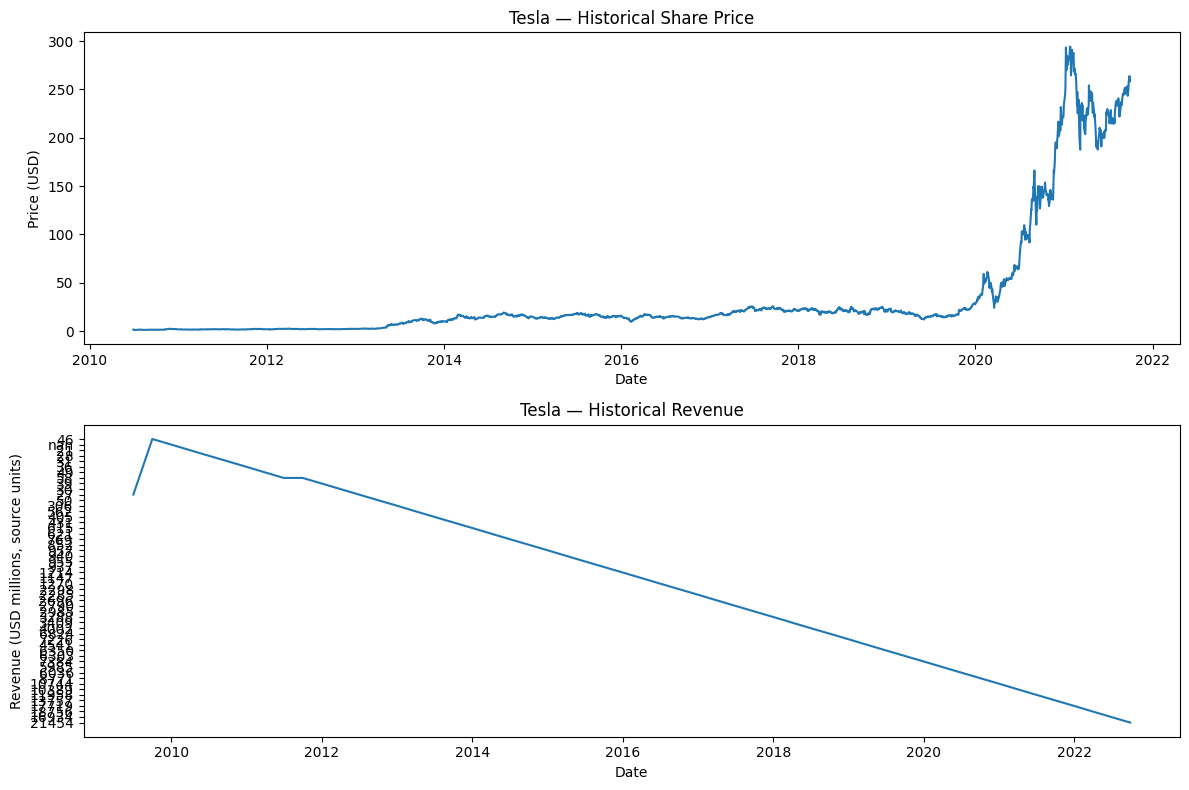

In [16]:
tesla_revenue["Date"] = pd.to_datetime(tesla_revenue["Date"], errors="coerce")
tesla_revenue.dropna(subset=["Date"], inplace=True)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(tesla_data["Date"], tesla_data["Close"])
axes[0].set_title("Tesla — Historical Share Price")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price (USD)")
axes[1].plot(tesla_revenue["Date"], tesla_revenue["Revenue"])
axes[1].set_title("Tesla — Historical Revenue")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Revenue (USD millions, source units)")
plt.tight_layout()
plt.show()


## Exercise 4 — Extract GameStop stock data

Download historical GameStop stock data and display the first five records.

In [17]:
gme = yf.Ticker("GME")
gme_data = gme.history(start="2002-02-13", end="2021-10-01")
gme_data.reset_index(inplace=True)
gme_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615921,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Exercise 5 — Extract GameStop revenue data

Scrape and clean GameStop's revenue table.

In [19]:

import pandas as pd
import requests
from io import StringIO

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

response = requests.get(url, timeout=30)
response.raise_for_status()

html_data = response.text

gme_revenue = pd.read_html(
    StringIO(html_data),
    match="GameStop Quarterly Revenue"
)[0]

gme_revenue.columns = ["Date", "Revenue"]

gme_revenue["Revenue"] = (
    gme_revenue["Revenue"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True)
)

gme_revenue["Revenue"] = pd.to_numeric(
    gme_revenue["Revenue"], errors="coerce"
)

gme_revenue.dropna(inplace=True)

gme_revenue.tail()


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Exercise 6 — Plot GameStop stock price and revenue

Plot GameStop's historical closing price and revenue. Compare the two charts and note that the large stock-price spike around 2021 is not matched by a similar revenue spike.

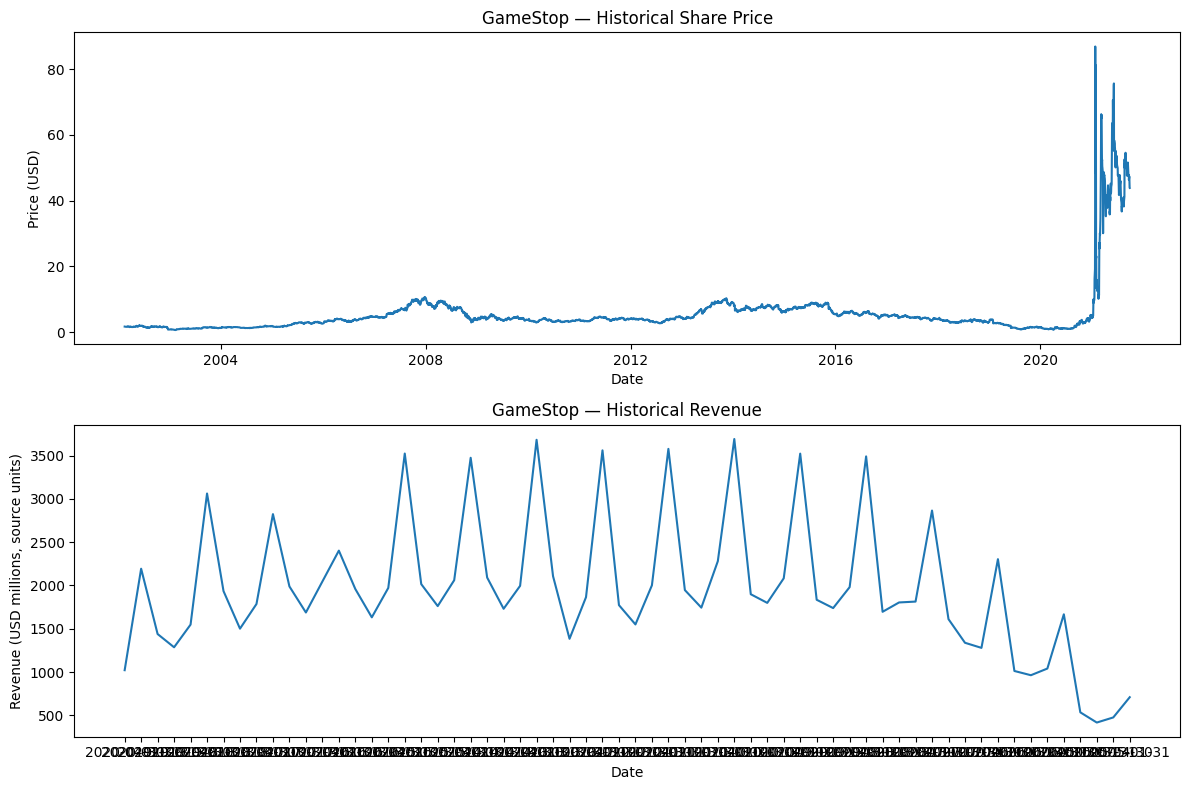

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(gme_data["Date"], gme_data["Close"])
axes[0].set_title("GameStop — Historical Share Price")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price (USD)")
axes[1].plot(gme_revenue["Date"], gme_revenue["Revenue"])
axes[1].set_title("GameStop — Historical Revenue")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Revenue (USD millions, source units)")
plt.tight_layout()
plt.show()


## Summary observations

- Tesla's stock price and revenue both show strong long-term growth through the period, though the stock price is more volatile.
- GameStop's share price shows a sharp surge around 2021, while revenue does not show a comparable spike.
- Stock price and company revenue measure different things; movements in share price do not necessarily track revenue directly.

**Submission checklist**
1. Run all cells from top to bottom.
2. Confirm every code cell has output and both plotting exercises display charts.
3. Save the notebook as `.ipynb`.
4. Upload the executed notebook to the Coursera assignment page.

**Troubleshooting:** If `pd.read_html()` reports that no tables were found or the website blocks the request, the website's markup/access policy may have changed. Use the course lab's supplied extraction source or dataset, then rerun the cleaning and plotting cells.